# RAF-DB — validation split, preprocessing and augmentation

Goal: prepare the RAF-DB dataset (7 basic emotions) so it can be fed to the custom CNN and to ResNet18.

**Order of steps and why it matters**

1. **Setup** – paths, constants and a fixed random seed, so every run gives the same result.
2. **Load file list + sanity checks** – count images, check sizes, find duplicate files.
3. **Split train → train + validation** – done *first*, before computing anything from the data, so the validation set stays truly unseen (no data leakage). The official test set is kept as it is.
4. **Save the split** to `data/processed` (the raw data in `RAF-DB/DATASET` is never modified).
5. **Preprocessing** – resize + normalize. Deterministic and identical for train, validation and test.
6. **Augmentation** – random transformations added **only** to the training pipeline and applied on-the-fly.
7. **Datasets & DataLoaders** + a check of the batch shapes.
8. **Visualization** of augmented samples.

## 1. Setup

All settings are in one place. `SEED` fixes the randomness of Python, NumPy and PyTorch, which makes the split and the augmentations reproducible.

In [1]:
import hashlib
import random
import shutil
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from PIL import Image
from sklearn.model_selection import train_test_split
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

RAW_DIR = Path("RAF-DB/DATASET")   # original dataset (read-only)
OUT_DIR = Path("data/processed")   # train / val / test after the split
VAL_SIZE = 0.15                    # 15% of the original train set goes to validation
IMG_SIZE = 224                     # input size of ImageNet-pretrained ResNet18
BATCH_SIZE = 64
NUM_WORKERS = 0                    # worker processes are slow to start / can hang in Jupyter on Windows

CLASS_NAMES = {
    "1": "Surprise", "2": "Fear", "3": "Disgust", "4": "Happiness",
    "5": "Sadness", "6": "Anger", "7": "Neutral",
}

if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")
print("PyTorch:", torch.__version__, "| device:", device)

PyTorch: 2.11.0+cpu | device: cpu


## 2. Load the file list and run sanity checks

The label of each image is the name of its folder (`1`–`7`). We build a table (`DataFrame`) with one row per image: its path, its label and an **MD5 hash** of the file content. Two files with the same hash are byte-for-byte identical images.

In [2]:
def list_images(split):
    """Return a DataFrame with one row per image: path, label (folder name) and content hash."""
    rows = []
    for class_dir in sorted((RAW_DIR / split).iterdir()):
        for path in sorted(class_dir.glob("*.jpg")):
            rows.append({
                "path": path,
                "label": class_dir.name,
                "md5": hashlib.md5(path.read_bytes()).hexdigest(),
            })
    return pd.DataFrame(rows)


train_full_df = list_images("train")
test_df = list_images("test")
print(f"train: {len(train_full_df)} images | test: {len(test_df)} images")

train: 12271 images | test: 3068 images


Check the size and color mode of every image. This tells us how much resizing is needed and whether any image must be converted to RGB.

In [3]:
def image_size_and_mode(path):
    with Image.open(path) as img:
        return img.size, img.mode


all_paths = pd.concat([train_full_df["path"], test_df["path"]])
all_paths.map(image_size_and_mode).value_counts().rename("images")

path
((100, 100), RGB)    15339
Name: images, dtype: int64

**Duplicates.** If the same image were in both train and validation, the model would be evaluated on an image it was trained on, which inflates the validation score (data leakage). We therefore keep only one copy of each duplicate in the training pool *before* splitting. We also check that no training image is identical to a test image.

The official test set is left unchanged, so our results stay comparable with other RAF-DB results. A duplicate *inside* the test set doesn't cause leakage.

In [4]:
print("Duplicate files inside train:")
display(train_full_df[train_full_df.duplicated("md5", keep=False)][["path", "label"]])
print("Duplicate files inside test:")
display(test_df[test_df.duplicated("md5", keep=False)][["path", "label"]])
print("Train images identical to a test image:", train_full_df["md5"].isin(test_df["md5"]).sum())

train_full_df = train_full_df.drop_duplicates("md5").reset_index(drop=True)
print("Train pool after removing duplicates:", len(train_full_df))

Duplicate files inside train:


,path,label
4394,RAF-DB\DATASET\train\4\train_03282_aligned.jpg,4
4397,RAF-DB\DATASET\train\4\train_03285_aligned.jpg,4
9702,RAF-DB\DATASET\train\6\train_08539_aligned.jpg,6
9703,RAF-DB\DATASET\train\6\train_08540_aligned.jpg,6


Duplicate files inside test:


,path,label
2808,RAF-DB\DATASET\test\7\test_2809_aligned.jpg,7
2809,RAF-DB\DATASET\test\7\test_2810_aligned.jpg,7


Train images identical to a test image: 0
Train pool after removing duplicates: 12269


## 3. Split train → train + validation

- The **validation set** is used during training to choose hyperparameters, compare models and pick the best epoch. The **test set** is used only once, for the final evaluation.
- `stratify=label` keeps the class proportions the same in train and validation. This matters here because *Fear* is only about 2% of the data, and a plain random split could leave very few Fear images in validation.
- `random_state=SEED` makes the split reproducible.

In [5]:
train_df, val_df = train_test_split(
    train_full_df,
    test_size=VAL_SIZE,
    stratify=train_full_df["label"],
    random_state=SEED,
)
splits = {"train": train_df, "val": val_df, "test": test_df}

for a, b in [("train", "val"), ("train", "test"), ("val", "test")]:
    shared = set(splits[a]["md5"]) & set(splits[b]["md5"])
    assert not shared, f"{a} and {b} share {len(shared)} images"
print("OK: no image appears in more than one split.")
print({name: len(df) for name, df in splits.items()})

OK: no image appears in more than one split.
{'train': 10428, 'val': 1841, 'test': 3068}


Compare the class distribution of the three splits. With stratification, the percentages in train and val should be (almost) identical.

count                %            
            train  val  test train   val  test
1 Surprise   1097  193   329  10.5  10.5  10.7
2 Fear        239   42    74   2.3   2.3   2.4
3 Disgust     609  108   160   5.8   5.9   5.2
4 Happiness  4055  716  1185  38.9  38.9  38.6
5 Sadness    1685  297   478  16.2  16.1  15.6
6 Anger       598  106   162   5.7   5.8   5.3
7 Neutral    2145  379   680  20.6  20.6  22.2

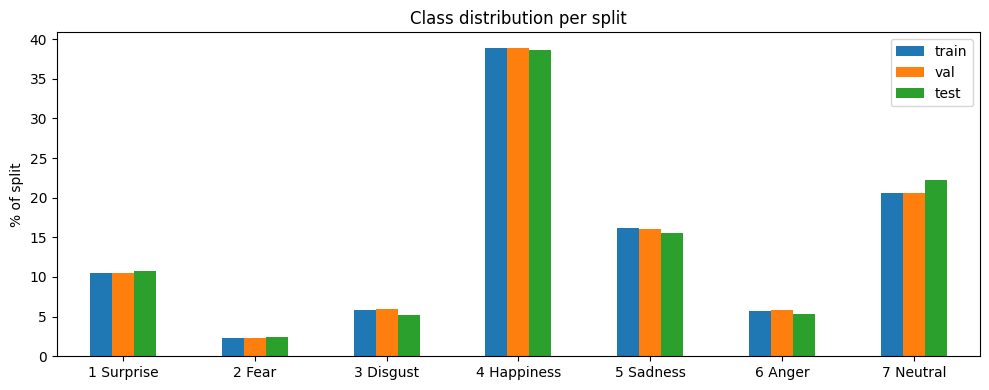

In [6]:
counts = pd.DataFrame({name: df["label"].value_counts() for name, df in splits.items()}).sort_index()
counts.index = [f"{label} {CLASS_NAMES[label]}" for label in counts.index]
percent = (counts / counts.sum() * 100).round(1)
display(pd.concat({"count": counts, "%": percent}, axis=1))

percent.plot.bar(figsize=(10, 4), rot=0, title="Class distribution per split")
plt.ylabel("% of split")
plt.tight_layout()
plt.show()

The class proportions are preserved in all three splits. The dataset is strongly **imbalanced**: Happiness is about 39% of the images and Fear about 2%. We don't fix this by changing the data. It will be handled during training (for example with class weights computed from the *train* split) and evaluation (macro-F1 instead of accuracy alone).

## 4. Save the split to disk

The images are copied into `data/processed/{train,val,test}/{1..7}/`. Later notebooks can then load each split directly with `torchvision.datasets.ImageFolder`, and the split stays fixed. A CSV manifest records which original file went to which split.

In [7]:
if OUT_DIR.exists():
    shutil.rmtree(OUT_DIR)  # rebuild from scratch so re-running never leaves stale files

manifest = []
for split_name, df in splits.items():
    for row in df.itertuples():
        dst = OUT_DIR / split_name / row.label / row.path.name
        dst.parent.mkdir(parents=True, exist_ok=True)
        shutil.copy2(row.path, dst)
        manifest.append({
            "split": split_name,
            "label": row.label,
            "emotion": CLASS_NAMES[row.label],
            "source": row.path.as_posix(),
            "file": dst.as_posix(),
        })

pd.DataFrame(manifest).to_csv(OUT_DIR / "split_manifest.csv", index=False)
for split_name in splits:
    n_files = sum(1 for _ in (OUT_DIR / split_name).rglob("*.jpg"))
    print(f"{split_name}: {n_files} files")

train: 10428 files
val: 1841 files
test: 3068 files


## 5. Preprocessing: resize + normalize

Preprocessing is **deterministic**: the same image always gives the same tensor. It is applied in exactly the same way to train, validation and test.

- **`Resize((224, 224))`**: all images are 100×100, and ResNet18 was pretrained on 224×224 ImageNet images. Upscaling doesn't add detail, but it puts the facial features at the scale the pretrained filters learned. For the custom CNN you can set `IMG_SIZE = 100`, which keeps the original resolution and trains faster.
- **`ToTensor()`**: converts a PIL image (H×W×C, values 0–255) into a float tensor (C×H×W, values 0–1).
- **`Normalize(mean, std)`**: computes `(x − mean) / std` for each color channel, so inputs are centered around 0 with similar spread. This makes training more stable.

**Which mean/std?** The pretrained ResNet18 weights expect inputs normalized with **ImageNet** statistics, so we use those. If you compute your own statistics, use the **training split only**. Statistics computed with validation or test images would leak information about them into training. Below we compute the RAF-DB train statistics only to compare them with ImageNet.

In [8]:
channel_sum = np.zeros(3)
channel_sq_sum = np.zeros(3)
n_pixels = 0
for path in train_df["path"]:
    img = np.asarray(Image.open(path).convert("RGB"), dtype=np.float64) / 255.0
    channel_sum += img.sum(axis=(0, 1))
    channel_sq_sum += (img ** 2).sum(axis=(0, 1))
    n_pixels += img.shape[0] * img.shape[1]

train_mean = channel_sum / n_pixels
train_std = np.sqrt(channel_sq_sum / n_pixels - train_mean ** 2)

IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]
print("RAF-DB train mean:", train_mean.round(3), " std:", train_std.round(3))
print("ImageNet     mean:", IMAGENET_MEAN, " std:", IMAGENET_STD)

NORM_MEAN, NORM_STD = IMAGENET_MEAN, IMAGENET_STD

RAF-DB train mean: [0.576 0.449 0.401]  std: [0.265 0.242 0.241]
ImageNet     mean: [0.485, 0.456, 0.406]  std: [0.229, 0.224, 0.225]


The preprocessing pipeline for **validation and test** contains no randomness:

In [9]:
eval_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(NORM_MEAN, NORM_STD),
])

## 6. Augmentation (train set only)

Augmentation makes random but realistic variations of the training images. This way the model learns features that generalize instead of memorizing specific images, which reduces overfitting.

Rules we follow:
- **Only on train.** Validation and test must stay fixed and look like real data. Otherwise their scores would change randomly and couldn't be compared between epochs or models.
- **On-the-fly.** In every epoch each image gets a new random variant. Nothing is saved to disk, so the dataset doesn't grow.
- **The label must stay correct.** Use only mild changes. Faces are never upside down, so there is no vertical flip, and strong distortions could change the emotion we perceive.

| Transform | Why it makes sense for faces |
|---|---|
| `RandomHorizontalFlip` | a mirrored face shows the same emotion |
| `RandomAffine` (±10°, shift 5%, zoom 95–105%) | head tilt and imperfect face alignment |
| `ColorJitter` (brightness/contrast/saturation) | different lighting, cameras and photo filters |
| `RandomErasing` | partial occlusions (hands, glasses, hair) |

**Order:** first the same `Resize` as in preprocessing. Then come the augmentations that work on PIL images, then `ToTensor` + `Normalize` (the same as for val/test). `RandomErasing` works on tensors, so it goes last.

In [10]:
train_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomAffine(degrees=10, translate=(0.05, 0.05), scale=(0.95, 1.05)),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
    transforms.ToTensor(),
    transforms.Normalize(NORM_MEAN, NORM_STD),
    transforms.RandomErasing(p=0.25, scale=(0.02, 0.10)),
])

## 7. Datasets and DataLoaders

- `ImageFolder` reads the folder structure: each sub-folder is a class. Folders `1`–`7` become class indices `0`–`6`.
- The **train** dataset gets `train_transform`. **Val** and **test** get `eval_transform`.
- `DataLoader` groups images into batches. Only the train loader uses `shuffle=True`, so the model doesn't see the classes in a fixed order. Evaluation doesn't need shuffling. The seeded `generator` makes the shuffling reproducible.

In [11]:
train_ds = datasets.ImageFolder(OUT_DIR / "train", transform=train_transform)
val_ds = datasets.ImageFolder(OUT_DIR / "val", transform=eval_transform)
test_ds = datasets.ImageFolder(OUT_DIR / "test", transform=eval_transform)

assert train_ds.class_to_idx == val_ds.class_to_idx == test_ds.class_to_idx
idx_to_emotion = {idx: CLASS_NAMES[folder] for folder, idx in train_ds.class_to_idx.items()}
print("Class index -> emotion:", idx_to_emotion)

loader_args = dict(batch_size=BATCH_SIZE, num_workers=NUM_WORKERS, pin_memory=device.type == "cuda")
train_loader = DataLoader(train_ds, shuffle=True, generator=torch.Generator().manual_seed(SEED), **loader_args)
val_loader = DataLoader(val_ds, shuffle=False, **loader_args)
test_loader = DataLoader(test_ds, shuffle=False, **loader_args)

for name, ds, loader in [("train", train_ds, train_loader), ("val", val_ds, val_loader), ("test", test_ds, test_loader)]:
    print(f"{name:5s}: {len(ds):5d} images, {len(loader):3d} batches")

Class index -> emotion: {0: 'Surprise', 1: 'Fear', 2: 'Disgust', 3: 'Happiness', 4: 'Sadness', 5: 'Anger', 6: 'Neutral'}
train: 10428 images, 163 batches
val  :  1841 images,  29 batches
test :  3068 images,  48 batches


Check one batch. Images should have shape `[batch, 3, 224, 224]` and type `float32`, and their values should be roughly centered around 0 after normalization.

In [12]:
images, labels = next(iter(train_loader))
print("images:", tuple(images.shape), images.dtype)
print("labels:", tuple(labels.shape), labels.dtype, "| first 10:", labels[:10].tolist())
print(f"pixel values: min {images.min():.2f}, max {images.max():.2f}, mean {images.mean():.2f}")

images: (64, 3, 224, 224) torch.float32
labels: (64,) torch.int64 | first 10: [3, 3, 3, 5, 3, 6, 3, 6, 4, 1]
pixel values: min -2.12, max 2.64, mean -0.00


## 8. Visualize samples after augmentation

This visual check confirms that the augmentations look realistic and don't destroy the facial expression. To display a tensor we first **undo the normalization** (`x · std + mean`). Then we move the channel axis to the end (C×H×W → H×W×C), because `matplotlib` expects that layout.

In [13]:
def denormalize(tensor):
    """Undo Normalize and convert a C×H×W tensor into an H×W×C array for plt.imshow."""
    mean = torch.tensor(NORM_MEAN).view(3, 1, 1)
    std = torch.tensor(NORM_STD).view(3, 1, 1)
    return (tensor * std + mean).clamp(0, 1).permute(1, 2, 0).numpy()

**One training image per emotion.** The first column shows the image after preprocessing only, which is what val/test images look like. The other columns show 5 random augmented versions of the same image, as the model might see it in 5 different epochs.

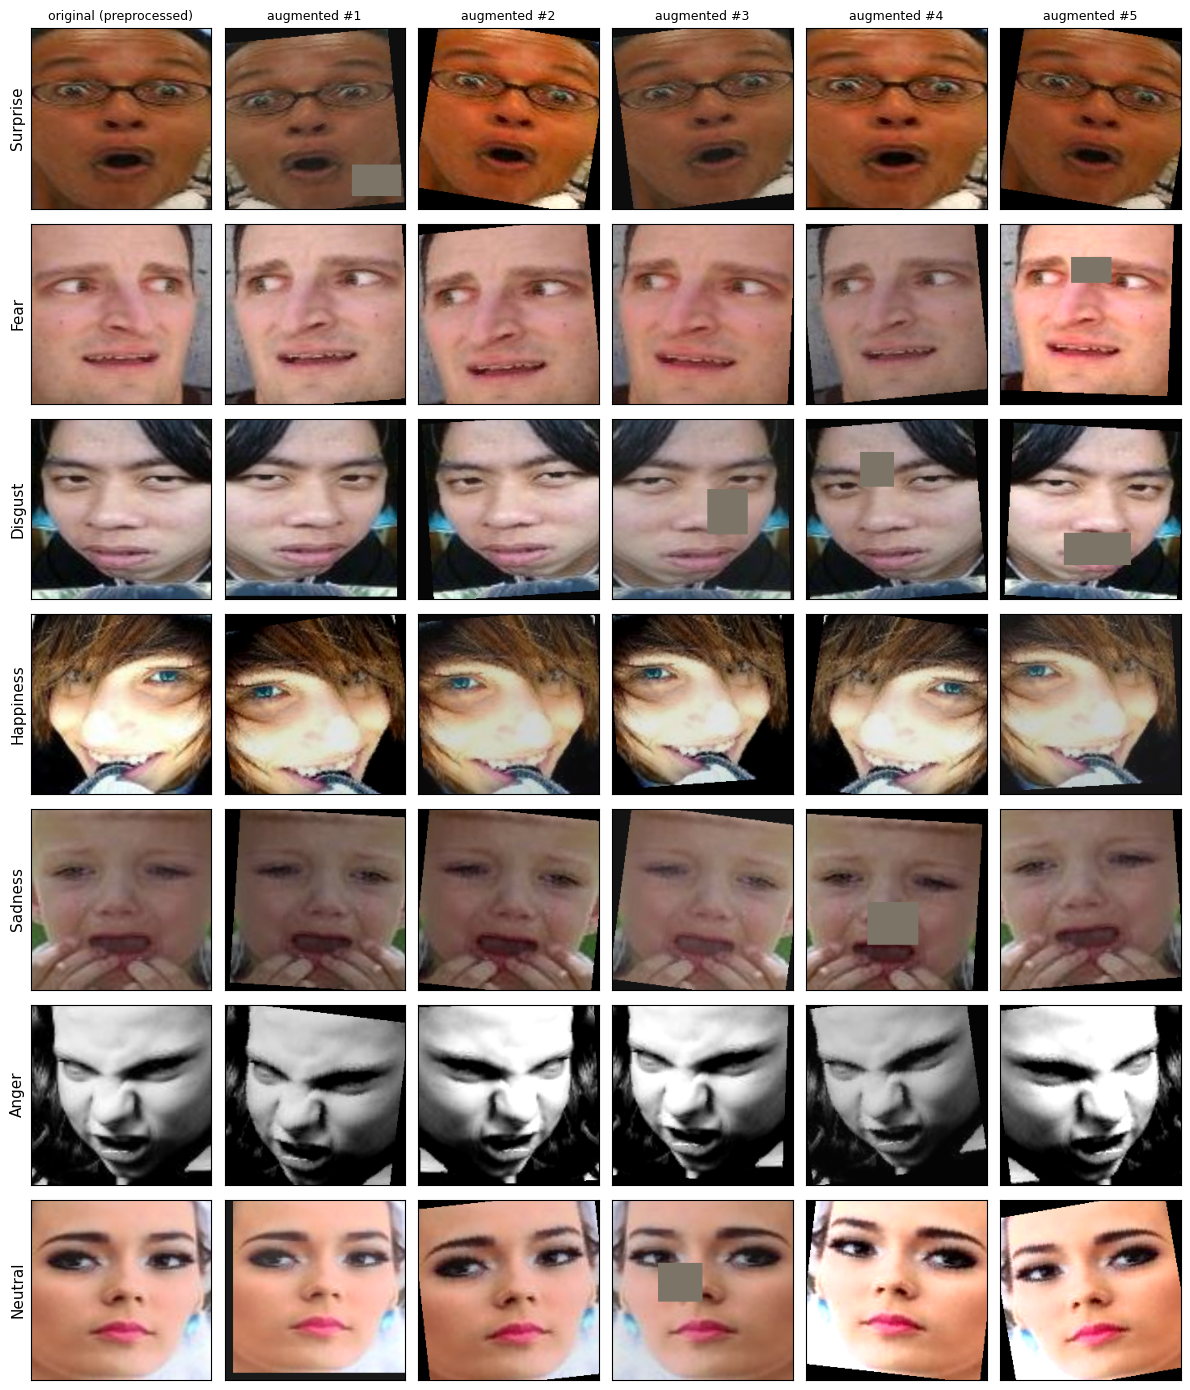

In [14]:
N_AUGMENTED = 5
rng = random.Random(SEED)
n_classes = len(idx_to_emotion)
fig, axes = plt.subplots(n_classes, N_AUGMENTED + 1, figsize=(2 * (N_AUGMENTED + 1), 2 * n_classes))

for class_idx, emotion in idx_to_emotion.items():
    path, _ = rng.choice([s for s in train_ds.samples if s[1] == class_idx])
    img = Image.open(path).convert("RGB")
    versions = [eval_transform(img)] + [train_transform(img) for _ in range(N_AUGMENTED)]

    for col, tensor in enumerate(versions):
        ax = axes[class_idx, col]
        ax.imshow(denormalize(tensor))
        ax.set_xticks([])
        ax.set_yticks([])
        if class_idx == 0:
            ax.set_title("original (preprocessed)" if col == 0 else f"augmented #{col}", fontsize=9)
    axes[class_idx, 0].set_ylabel(emotion, fontsize=11)

plt.tight_layout()
plt.show()

**A random training batch** exactly as the `DataLoader` delivers it to the model (after preprocessing + augmentation).

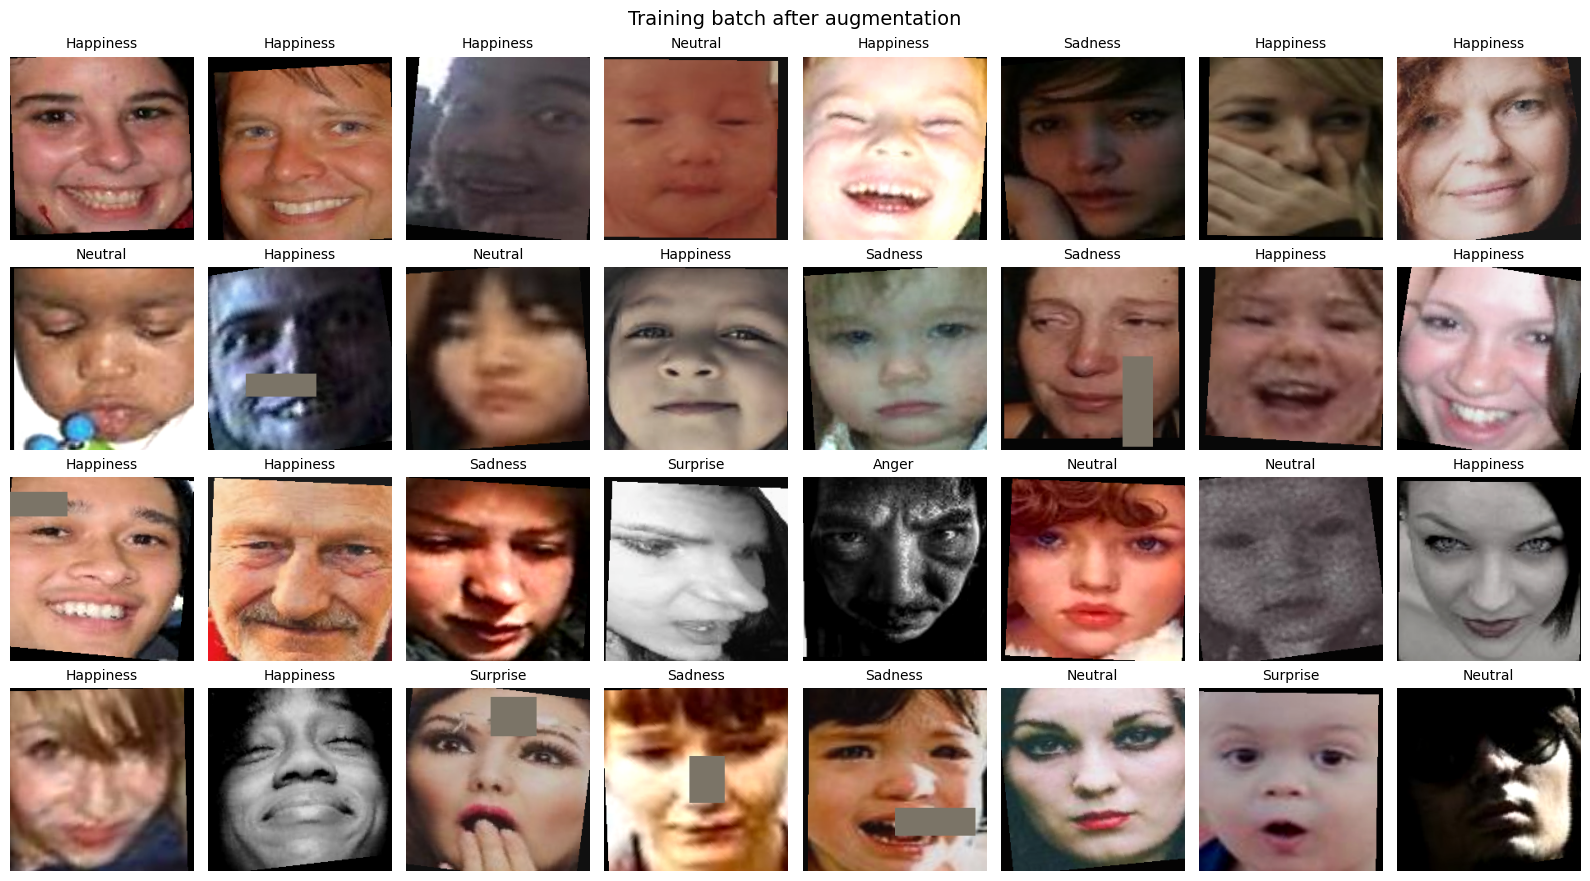

In [15]:
images, labels = next(iter(train_loader))
fig, axes = plt.subplots(4, 8, figsize=(16, 9))
for ax, img, label in zip(axes.flat, images, labels):
    ax.imshow(denormalize(img))
    ax.set_title(idx_to_emotion[label.item()], fontsize=10)
    ax.axis("off")
fig.suptitle("Training batch after augmentation", fontsize=14)
plt.tight_layout()
plt.show()

## Summary

- **Validation split:** 15% of the original train set, stratified by class and reproducible (`SEED`). Exact duplicates were removed, and the splits were checked to share no images.
- **Saved on disk:** `data/processed/{train,val,test}` plus `split_manifest.csv`. The raw data is unchanged.
- **Preprocessing (all splits):** resize to 224×224, convert to a tensor, normalize with ImageNet mean/std.
- **Augmentation (train only, on-the-fly):** horizontal flip, small rotation/shift/zoom, color jitter, random erasing.
- **Ready for training:** `train_loader`, `val_loader`, `test_loader` and `idx_to_emotion`.

Next step: model training. Handle the class imbalance there with class weights computed from the train split, and track macro-F1.